**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage.filters import sobel
from sklearn.metrics import accuracy_score

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits, train_and_evaluate_classifier
from src.representation import compute_hog, HOG_PARAMS

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

**Célula 2 – figura: original vs contornos (Sobel) vs HOG:**

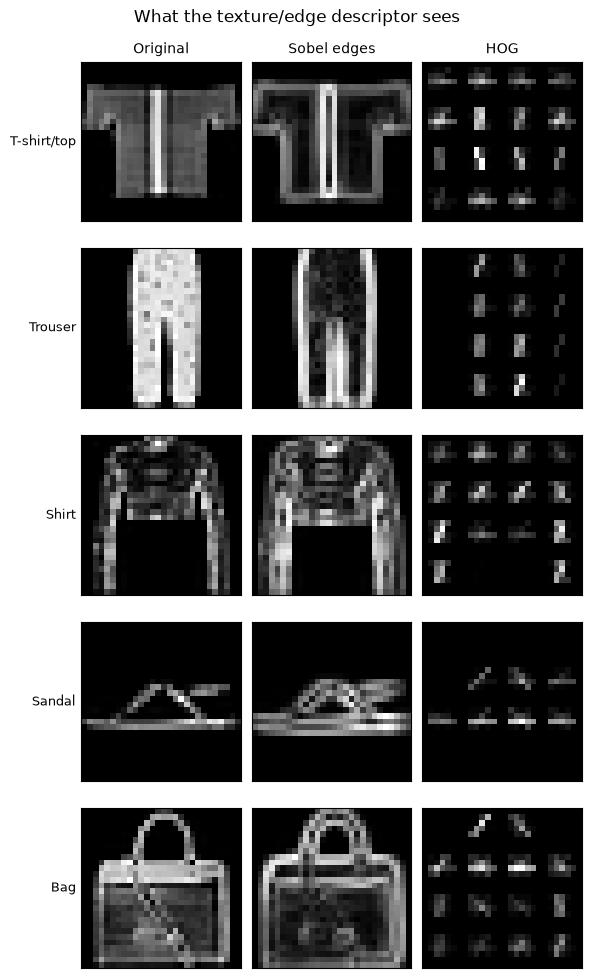

In [2]:
rng = np.random.default_rng(SEED)
example_idx = np.array([rng.choice(np.where(y_test == c)[0]) for c in range(10)])
chosen_classes = [0, 1, 6, 5, 8]     

fig, axes = plt.subplots(len(chosen_classes), 3, figsize=(6, 2 * len(chosen_classes)))
for r, c in enumerate(chosen_classes):
    img = X_test[example_idx[c]].reshape(28, 28)
    edges = sobel(img)                                              
    _, hog_img = hog(img, visualize=True, **HOG_PARAMS)           
    for ax, im, title in zip(axes[r], [img, edges, hog_img], ["Original", "Sobel edges", "HOG"]):
        ax.imshow(im, cmap="gray")
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(title, fontsize=10)
    axes[r, 0].set_ylabel(CLASS_NAMES[c], fontsize=9, rotation=0, ha="right", va="center")

plt.suptitle("What the texture/edge descriptor sees")
plt.tight_layout()
plt.savefig("results/figures/10_sobel_hog_examples.png", dpi=150, bbox_inches="tight")
plt.show()

**Célula 3 – calcular o HOG para todas as imagens:**

In [3]:
start = time.perf_counter()
H_train, H_val, H_test = (compute_hog(X) for X in (X_train, X_val, X_test))
print(f"HOG calculado em {time.perf_counter() - start:.1f} s")
print("Formas:", H_train.shape, H_val.shape, H_test.shape)

HOG calculado em 37.1 s
Formas: (50000, 324) (10000, 324) (10000, 324)


**Célula 4 – classificar com HOG (mesmo classificador das Etapas 3 e 9):**

In [4]:
clf_hog, test_acc, t = train_and_evaluate_classifier(H_train, y_train, H_test, y_test)
val_acc = accuracy_score(y_val, clf_hog.predict(H_val))
print(f"HOG (324 dim) -> val = {val_acc:.4f} | test = {test_acc:.4f} | treino em {t:.1f} s")

pd.DataFrame([{"space": "HOG", "dim": H_train.shape[1], "val_acc": val_acc,
               "test_acc": test_acc, "train_time_s": t}]) \
  .to_csv("results/tables/10_hog_classification.csv", index=False)

HOG (324 dim) -> val = 0.8566 | test = 0.8444 | treino em 105.8 s
